# Result Visualization

Compares Clean Accuracy (CA), Attack Success Rate (ASR) and stealthiness (SSIM / PSNR / L2 / L∞ /
LPIPS) across every attack and poisoning rate. Figures are saved to `results/figures/` for the report.

**Data source.** `results/summary.csv` is an append-only log: it contains repeated runs, and its
`attack` column cannot tell clean-label SIG from dirty-label SIG (both are logged as `sig`). The
plots therefore read `results/report_results.csv`, a curated table with one row per
(attack, poison rate) that matches Tables 1 and 2 of the report. Section 0 cross-checks it against
the latest matching rows of `summary.csv`.

Contents
0. Consistency check against `summary.csv`
1. ASR vs. poisoning rate (all attacks)
2. Clean accuracy
3. Stealthiness vs. effectiveness trade-off
4. Fixed vs. Adaptive SIG+WaNet (v1 and v2)
5. Adaptive ablation

In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FIG_DIR = "results/figures"
os.makedirs(FIG_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9})

df = pd.read_csv("results/report_results.csv")
RATES = [0.005, 0.01, 0.05]
RATE_LABELS = ["0.5%", "1%", "5%"]
COLORS = {
    "Blend": "#1f77b4", "SIG (clean-label)": "#aec7e8", "SIG (dirty-label)": "#ff7f0e", "WaNet": "#2ca02c",
    "Blend+SIG": "#9467bd", "Blend+WaNet": "#8c564b", "SIG+WaNet (Fixed)": "#17becf", "Blend+SIG+WaNet": "#7f7f7f",
    "Adaptive v1": "#d62728", "Adaptive v2": "#2e7d32",
    "Adaptive spatial-only (v1 settings)": "#e377c2", "Adaptive freq-only (v1 settings)": "#bcbd22",
}
df.pivot_table(index="attack", columns="poison_rate", values="asr", sort=False)

poison_rate,0.005,0.010,0.050
attack,,,
Blend,85.48,96.50,99.83
SIG (clean-label),27.80,65.33,89.90
SIG (dirty-label),97.56,98.97,99.96
WaNet,29.73,53.92,94.73
Blend+SIG,85.86,95.36,99.43
Blend+WaNet,63.19,83.72,98.34
SIG+WaNet (Fixed),87.36,95.28,99.01
Blend+SIG+WaNet,78.33,89.62,97.79
Adaptive v1,97.80,99.34,99.94


## 0. Consistency check against `summary.csv`

For attack names that are unambiguous in `summary.csv`, take the **most recent** row per
(attack, poison rate) and compare it with the curated table. Agreement confirms the curated
numbers come from the evaluation runs.

In [2]:
# summary.csv was started with a 6-column header; later rows have 9 fields (L2/Linf/LPIPS added)
raw = pd.read_csv("results/summary.csv", skiprows=1, header=None,
                  names=["attack", "poison_rate", "clean_acc", "asr", "ssim", "psnr", "l2", "linf", "lpips"])
name_map = {"blend": "Blend", "sig_wanet": "SIG+WaNet (Fixed)", "blend_wanet": "Blend+WaNet", "blend_sig_wanet": "Blend+SIG+WaNet",
            "adaptive_hybrid": "Adaptive v2", "adaptive_spatial": "Adaptive spatial-only (v1 settings)",
            "adaptive_freq": "Adaptive freq-only (v1 settings)"}
latest = (raw[raw.attack.isin(name_map)].groupby(["attack", "poison_rate"]).tail(1)
          .assign(attack=lambda d: d.attack.map(name_map)))
cmp = latest.merge(df, on=["attack", "poison_rate"], suffixes=("_summary", "_report"))
cmp["asr_summary"] *= 100; cmp["clean_acc_summary"] *= 100
cmp["asr_diff"] = (cmp.asr_summary - cmp.asr_report).round(2)
cmp["ssim_diff"] = (cmp.ssim_summary - cmp.ssim_report).round(4)
cmp[["attack", "poison_rate", "asr_report", "asr_summary", "asr_diff", "ssim_report", "ssim_summary", "ssim_diff"]].round(4)

,attack,poison_rate,asr_report,asr_summary,asr_diff,ssim_report,ssim_summary,ssim_diff
0,Adaptive spatial-only (v1 settings),0.010,50.03,50.0333,0.0,0.9588,0.9588,0.0
1,Adaptive spatial-only (v1 settings),0.050,92.78,92.7778,-0.0,0.9588,0.9588,0.0
2,Adaptive spatial-only (v1 settings),0.005,7.40,7.4000,0.0,0.9588,0.9588,0.0
3,Adaptive freq-only (v1 settings),0.010,98.76,98.7556,-0.0,0.9290,0.9290,-0.0
4,Adaptive freq-only (v1 settings),0.050,99.86,99.8556,-0.0,0.9290,0.9290,-0.0
5,Adaptive freq-only (v1 settings),0.005,96.16,96.1556,-0.0,0.9290,0.9290,-0.0
6,Blend+WaNet,0.005,63.19,63.1889,-0.0,0.9447,0.9447,0.0
7,Blend+WaNet,0.010,83.72,83.7222,0.0,0.9447,0.9447,0.0
8,Blend+WaNet,0.050,98.34,98.3444,0.0,0.9447,0.9447,0.0
9,SIG+WaNet (Fixed),0.005,87.36,87.3556,-0.0,0.9379,0.9379,0.0


Any non-zero difference above means a newer `summary.csv` row exists for that configuration
(e.g. a re-evaluation); the report table records the run used in the write-up.

## 1. ASR vs. poisoning rate

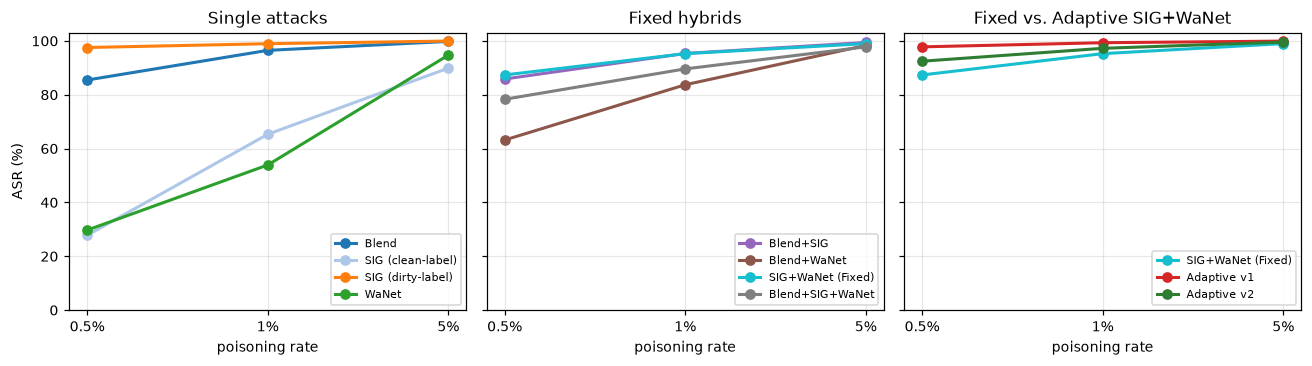

In [3]:
groups = {"Single attacks": ["Blend", "SIG (clean-label)", "SIG (dirty-label)", "WaNet"],
          "Fixed hybrids": ["Blend+SIG", "Blend+WaNet", "SIG+WaNet (Fixed)", "Blend+SIG+WaNet"],
          "Fixed vs. Adaptive SIG+WaNet": ["SIG+WaNet (Fixed)", "Adaptive v1", "Adaptive v2"]}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, (title, names) in zip(axes, groups.items()):
    for n in names:
        sub = df[df.attack == n].sort_values("poison_rate")
        ax.plot(range(3), sub.asr, marker="o", color=COLORS[n], label=n, lw=2)
    ax.set_xticks(range(3)); ax.set_xticklabels(RATE_LABELS); ax.set_xlabel("poisoning rate")
    ax.set_title(title); ax.grid(alpha=0.3); ax.legend(fontsize=7, loc="lower right")
axes[0].set_ylabel("ASR (%)"); axes[0].set_ylim(0, 103)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/asr_vs_poison_rate.png", bbox_inches="tight"); plt.show()

## 2. Clean accuracy

Every backdoored model stays within about ±1 point of the clean baseline (dashed line), so the
backdoors cannot be detected from validation accuracy alone.

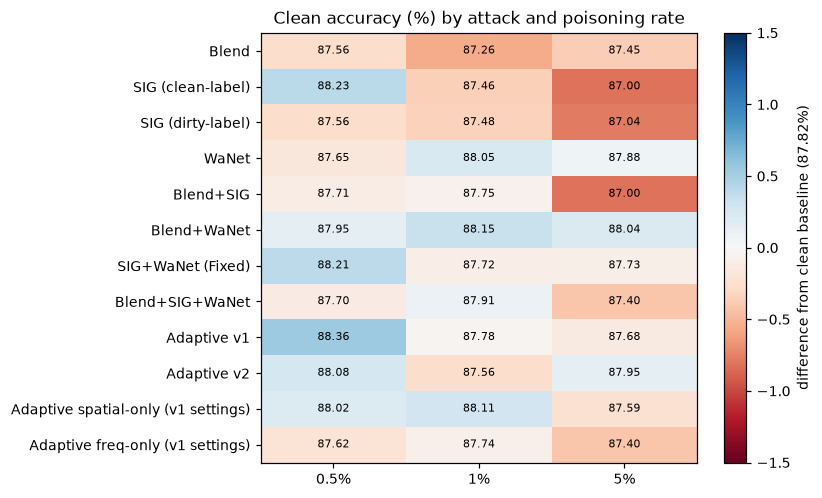

In [4]:
ca = df[df.group != "baseline"].pivot_table(index="attack", columns="poison_rate", values="clean_acc", sort=False)
baseline = df.loc[df.group == "baseline", "clean_acc"].item()
fig, ax = plt.subplots(figsize=(7.5, 4.6))
im = ax.imshow(ca.values - baseline, cmap="RdBu", vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(3)); ax.set_xticklabels(RATE_LABELS); ax.set_yticks(range(len(ca))); ax.set_yticklabels(ca.index)
for i in range(ca.shape[0]):
    for j in range(ca.shape[1]):
        ax.text(j, i, f"{ca.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, label=f"difference from clean baseline ({baseline:.2f}%)")
ax.set_title("Clean accuracy (%) by attack and poisoning rate")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/clean_accuracy.png", bbox_inches="tight"); plt.show()

## 3. Stealthiness vs. effectiveness

Each point is one attack at a given poisoning rate. **Top-right is better** (high ASR and high SSIM
or PSNR). At 0.5% the trade-off is clearest: attacks are either effective (Blend, SIG) or stealthy
(WaNet, three-way hybrid). Adaptive v2 moves the SIG+WaNet hybrid up and to the right of the Fixed
version.

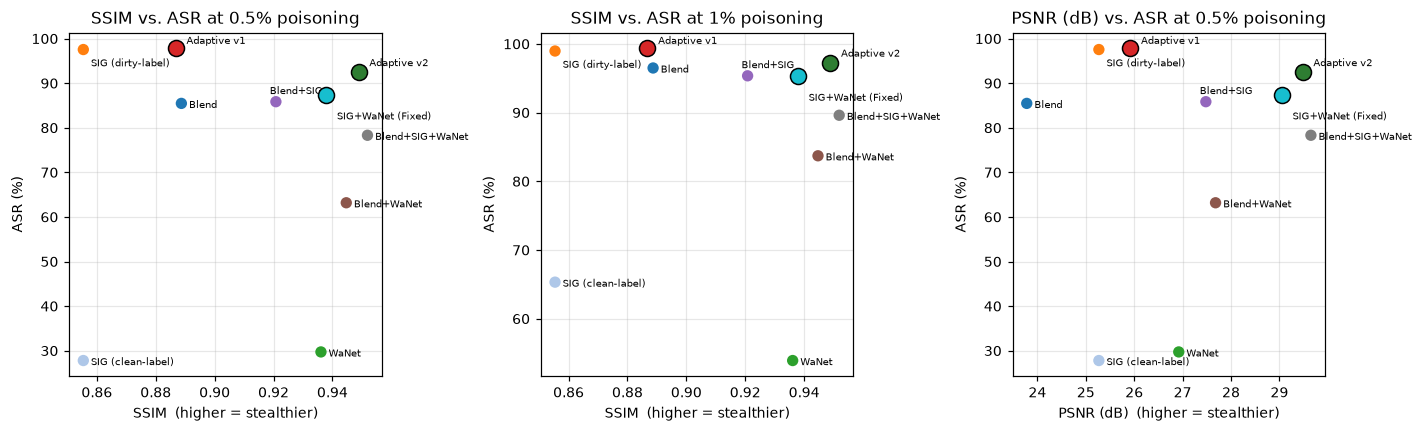

In [5]:
plot_names = [n for n in COLORS if "only" not in n]
# label offsets (points) for points that would otherwise overlap
OFFSETS = {"SIG (dirty-label)": (5, -11), "Adaptive v1": (7, 3), "Adaptive v2": (7, 4),
           "SIG+WaNet (Fixed)": (7, -16), "Blend+SIG": (-4, 5)}
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (rate, metric, label) in zip(axes, [(0.005, "ssim", "SSIM"), (0.01, "ssim", "SSIM"), (0.005, "psnr", "PSNR (dB)")]):
    sub = df[(df.poison_rate == rate) & df.attack.isin(plot_names)]
    for _, r in sub.iterrows():
        big = r.attack.startswith("Adaptive") or "Fixed" in r.attack
        ax.scatter(r[metric], r.asr, s=110 if big else 55, color=COLORS[r.attack],
                   edgecolor="k" if big else "none", zorder=3)
        ax.annotate(r.attack, (r[metric], r.asr), fontsize=6.5,
                    xytext=OFFSETS.get(r.attack, (5, -3)), textcoords="offset points")
    ax.set_xlabel(label + "  (higher = stealthier)"); ax.set_ylabel("ASR (%)")
    ax.set_title(f"{label} vs. ASR at {rate:.1%} poisoning".replace(".0%", "%")); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/stealth_vs_asr.png", bbox_inches="tight"); plt.show()

## 4. Fixed vs. Adaptive SIG+WaNet

Left: ASR at each poisoning rate. Right: each stealthiness metric relative to the Fixed hybrid
(>1 = stealthier than Fixed; distance metrics are inverted so that higher is always better).

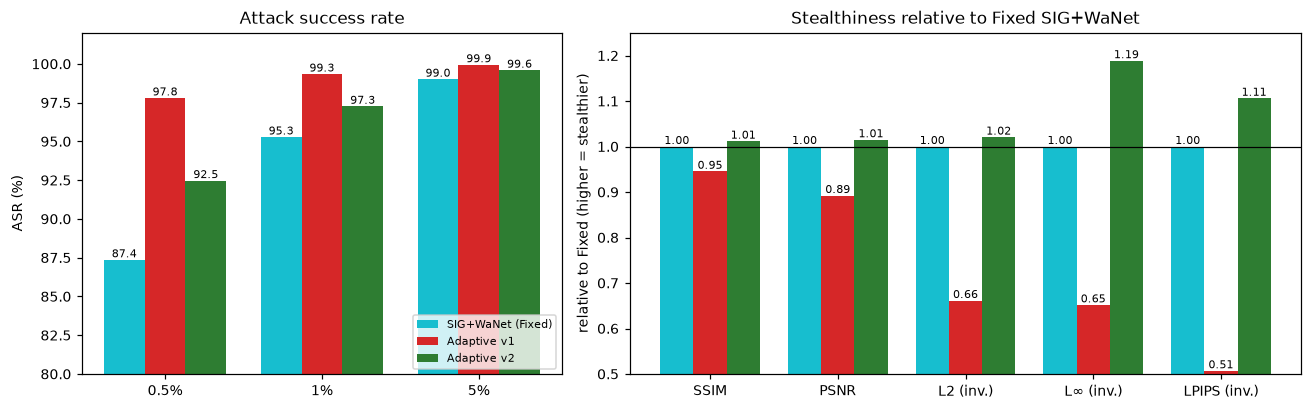

,clean_acc,ssim,psnr,l2,linf,lpips
attack,,,,,,
SIG+WaNet (Fixed),87.72,0.9379,29.05,1.9723,0.1739,0.0146
Adaptive v1,87.78,0.8868,25.92,2.9821,0.2668,0.0288
Adaptive v2,87.56,0.9489,29.48,1.9324,0.1463,0.0132


In [6]:
names = ["SIG+WaNet (Fixed)", "Adaptive v1", "Adaptive v2"]
sub = df[df.attack.isin(names)]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1.4]})
w = 0.26
for k, n in enumerate(names):
    vals = sub[sub.attack == n].sort_values("poison_rate").asr.values
    bars = axes[0].bar(np.arange(3) + (k - 1) * w, vals, w, color=COLORS[n], label=n)
    axes[0].bar_label(bars, fmt="%.1f", fontsize=7)
axes[0].set_xticks(range(3)); axes[0].set_xticklabels(RATE_LABELS); axes[0].set_ylim(80, 102)
axes[0].set_ylabel("ASR (%)"); axes[0].set_title("Attack success rate"); axes[0].legend(fontsize=7, loc="lower right")

metrics = [("ssim", "SSIM", False), ("psnr", "PSNR", False), ("l2", "L2", True), ("linf", "L∞", True), ("lpips", "LPIPS", True)]
one = sub[sub.poison_rate == 0.01].set_index("attack")
ref = one.loc["SIG+WaNet (Fixed)"]
for k, n in enumerate(names):
    rel = [(ref[m] / one.loc[n, m]) if inv else (one.loc[n, m] / ref[m]) for m, _, inv in metrics]
    bars = axes[1].bar(np.arange(len(metrics)) + (k - 1) * w, rel, w, color=COLORS[n], label=n)
    axes[1].bar_label(bars, fmt="%.2f", fontsize=7)
axes[1].axhline(1, color="k", lw=0.8)
axes[1].set_xticks(range(len(metrics))); axes[1].set_xticklabels([f"{l}" + (" (inv.)" if inv else "") for _, l, inv in metrics])
axes[1].set_ylabel("relative to Fixed (higher = stealthier)"); axes[1].set_ylim(0.5, 1.25)
axes[1].set_title("Stealthiness relative to Fixed SIG+WaNet")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fixed_vs_adaptive.png", bbox_inches="tight"); plt.show()

one[["clean_acc", "ssim", "psnr", "l2", "linf", "lpips"]].loc[names]

## 5. Adaptive ablation

The ablation variants use the original (v1) adaptive settings. The frequency (SIG) component on
its own nearly matches the full adaptive hybrid, while the spatial (WaNet) component alone is weak
at low poisoning rates. This is the evidence behind v2's design: it moves trigger budget from the
warp into the signal.

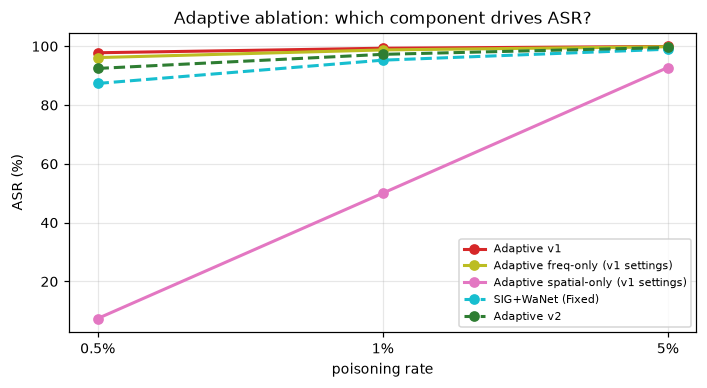

In [7]:
names = ["Adaptive v1", "Adaptive freq-only (v1 settings)", "Adaptive spatial-only (v1 settings)",
         "SIG+WaNet (Fixed)", "Adaptive v2"]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for n in names:
    s = df[df.attack == n].sort_values("poison_rate")
    ax.plot(range(3), s.asr, marker="o", lw=2, color=COLORS[n], label=n,
            ls="--" if n in ("SIG+WaNet (Fixed)", "Adaptive v2") else "-")
ax.set_xticks(range(3)); ax.set_xticklabels(RATE_LABELS); ax.set_xlabel("poisoning rate"); ax.set_ylabel("ASR (%)")
ax.set_title("Adaptive ablation: which component drives ASR?"); ax.grid(alpha=0.3); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/adaptive_ablation.png", bbox_inches="tight"); plt.show()